# homeassistant / weatherstation / battery

**Intent**
- Estimates `weatherstation_console_battery_capacity_pct` and `weatherstation_console_battery_capacity_pct_valid` from `weatherstation_console_battery_voltage` and `weatherstation_console_battery_voltage_valid`, and must:
  - Be fitted to recorded voltage curves.
  - Respond linearly and accurately, including the shoulders of the discharge and rapid voltage drops.
  - Hold steady in whole-percent steps a consumer can read at a glance, without bouncing.
  - React quickly to a battery replacement.
  - Hold across batteries, cycles and seasons.
  - Report zero capacity when readings stop.
  - Stay stable when its state is lost on a restart.
  - Give a floor a consumer can act on without the network.
  - Give an error for a missing voltage, and clamp out-of-range ones.
  - Report status 0 with zero capacity when the voltage is flagged not valid, so a consumer shows unavailable.

**Data**
- `training` is the 2024 run, 1,137 samples at 3 hour steps from 3.965 V down to the 3.000 V cutoff.
- It is digitised from the plot cached in git, revision 7ab8c7c7d, with pixels mapped through the axis ticks to about 0.003 V.
- It is a shape, not a measurement, and the arctans are fitted to it alone.
- The 36 Home Assistant polynomial points define the incumbent model 1000, and stay in Train as a named constant.
- Its capacity is the sample index rescaled from 100 to 0, so it assumes capacity falls linearly with time.
- `validation` is the 2026 run from InfluxDB, 813 on-change readings of one discharge.
- It runs from 4.17 V to a 3.76 to 3.80 V plateau, so it covers the top and the plateau only.
- Its `template_` column is the incumbent's deployed output, kept to check parity and never used as truth.
- Run 1000 is the 2024 shape and run 1001 the 2026 drain to 2026-10-30, both with guessed report times.
- Run 1002 extends the 2026 drain to 2026-11-09, with guessed report times except the last two and the incumbent from the old entity.
- Run 1003 is the 2026-11-08 battery swap, frozen, so the voltage jump of the replacement is captured.
- Run 1004 is live, refreshed every execution from the highest voltage after the swap, and only monitoring may use it.
- Every run carries `weatherstation_console_battery_voltage_valid` as 1, since a row exists only where a voltage was read.
- Runs 1000 to 1003 were rewritten with it, and list it as inferred.
- There is no `backtest` yet, since one discharge cannot be both validation and backtest.

**Status**
- The fixed-width arctan with a plateau shelf, in steps of 5, is released and served, and Home Assistant calls it.
- It is the only candidate inside the bounce limit of 60, and it needs the voltage valid flag from Home Assistant.
- Bounce is how often the output reverses direction on a one-way discharge.
- Its bounce is 41 against 215 without the shelf.
- The incumbent is model 1000, reproduces the deployed output exactly, and bounces 652 times.
- It gives up tracking the capacity across the 3.77 to 3.83 V plateau, where the cell dwells.
- No truth exists on a partial discharge, so agreement with the incumbent and linearity are reported and not gated.
- The shelf bounds come from the 2026 plateau in `validation`, a recorded exception to the held-out rule.
- So run 1005 re-gates it on a run the shelf has not seen, which makes the estimate independent.

**Future**
- Overall: the design holds across every phase:
  - Move to a stateful model that owns the smoothing, so Home Assistant sends the raw voltage, two timestamps and the saved state.
  - Smooth with a 1 hour exponential that decays the old reading through each gap and resets on a departure over 0.05 V.
  - Hold the output step with a margin of 1 point to fall and 3 to rise, explored at bounce 0 and rmse 4.34.
  - Carry four numbers of state, and accept that a restart loses it, about one extra flip in four restarts.
  - Detect silence in the model from the reported time and the clock, and report zero capacity.
  - Add a constant floor a consumer can act on without the network.
- Phase 1: now, while the current battery drains:
  - Build the stateful model as `wasm`, and replay run 1000 for training and run 1002 for validation to prove it.
  - State a golden tolerance on the arctan output, since the module imports `atan` from the host.
  - Write `atan` into the module instead, if the tolerance needed is wide enough to hide a real fault.
  - Release it as a refit that changes only the model file, since the released signature already carries its inputs.
  - Home Assistant already records every poll's report time in a helper, so cadence and silence can be replayed.
  - Run 1004 collects those report times, so compare them with the guesses in run 1002 to check the cadence assumption.
- Phase 2: when the current drain ends, about mid to late January 2027:
  - Wait for the drain to end and show the knee and the silence, which took about 140 days in 2024.
  - Hand build run 1005 of the whole drain, with real report times from run 1004 and guesses only before 2026-11-08.
  - Use run 1005 for validation in place of run 1002, stop refreshing run 1004, and retune the smoother and silence rule on it.
  - Re-gate the shelf arctan on run 1005, which its shelf bounds have not seen, so the pass is independent.
  - Gate on linearity of capacity against time on the full drain, since a partial discharge cannot show it.
- Phase 3: the next battery cycle, running to about June 2027:
  - Replace the battery once it is flat, which starts a fresh cycle of about 140 days and a third full drain.
  - Make that cycle the first `backtest`, judged once with no decision made on it, and move the gates to it.
  - The 2024 run may then leave training, and the refit releases change only the model file.
- Phase 4: ongoing, as runs accumulate over the years:
  - Allocate each run to one split when it starts and never move it, so the held-out runs stay honest.
  - Add each finished run as a committed hand built run, and keep Home Assistant recording every poll with no InfluxDB gaps.
  - Log each run's battery brand, batch, install date and start voltage, so curve differences trace to wear or charge.
  - Compare runs on capacity normalised over time, fitting one curve to their mean if they overlay, otherwise a per-battery offset.
  - Cross-validate by run, gate on the worst held-out run, and derive the shelf bounds from the dwell of those runs.
  - Give a new battery type its own training and validation runs and one full cycle before judging it as backtest.

## Setup ([6.7.1](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#671-setup))

In [1]:
from mlmodels import setup_workspace

ws = setup_workspace("homeassistant/weatherstation/battery")

Workspace homeassistant/weatherstation/battery
Target    served
Requires  []
Version   10.200.2027 (released)
Inputs    weatherstation_console_battery_voltage [volts]
          weatherstation_console_battery_voltage_valid [flag]
          weatherstation_console_battery_reported [seconds]
          weatherstation_console_battery_reported_valid [flag]
          clock_epoch_seconds [seconds]
Outputs   weatherstation_console_battery_capacity_pct [percent]
          weatherstation_console_battery_capacity_pct_valid [flag]
Data      1000 [2024-06-06 to 2024-10-25, full discharge, modelled] with rows [1137]
          1001 [2026-08-13 to 2026-10-30, part discharge, measured] with rows [813]
          1002 [2026-08-13 to 2026-11-09, part discharge, measured] with rows [889]
          1003 [2026-11-08 to 2026-11-09, batteries swap, measured] with rows [20]
          1004 [2026-11-09 to LIVE_QUERY, part discharge, measured] with rows [60]
Models    1000 [HASS polynomial] as [pyfunc]
          100

## Collect ([6.7.2](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#672-collect))

In [2]:
from mlmodels import collect_run

QUERY = """SELECT
  time,
  weatherstation_console_battery_voltage,
  CAST(1 AS BIGINT) AS weatherstation_console_battery_voltage_valid,
  CASE WHEN ABS(reported_next - CAST(to_unixtime(time) AS DOUBLE)) <= 120 THEN reported_next END AS weatherstation_console_battery_reported,
  template_weatherstation_console_battery_capacity_pct,
  mlserver_weatherstation_console_battery_capacity_pct
FROM (
  SELECT
    time,
    source,
    voltage AS weatherstation_console_battery_voltage,
    first_value(reported) IGNORE NULLS OVER (ORDER BY time, source ROWS BETWEEN CURRENT ROW AND UNBOUNDED FOLLOWING) AS reported_next,
    last_value(template) IGNORE NULLS OVER (ORDER BY time, source ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS template_weatherstation_console_battery_capacity_pct,
    last_value(mlserver) IGNORE NULLS OVER (ORDER BY time, source ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS mlserver_weatherstation_console_battery_capacity_pct
  FROM (
    SELECT time, 3 AS source, value AS voltage, CAST(NULL AS DOUBLE) AS reported, CAST(NULL AS DOUBLE) AS template, CAST(NULL AS DOUBLE) AS mlserver
    FROM sensor__voltage
    WHERE module = 'homeassistant'
      AND entity_id = 'weatherstation_console_battery_voltage'
      AND time >= '{start}'
      AND time < '{end}'
    UNION ALL
    SELECT time, 2 AS source, CAST(NULL AS DOUBLE) AS voltage, value AS reported, CAST(NULL AS DOUBLE) AS template, CAST(NULL AS DOUBLE) AS mlserver
    FROM input_number
    WHERE entity_id = 'weatherstation_console_battery_reported'
      AND time < '{end}'
    UNION ALL
    SELECT time, 1 AS source, CAST(NULL AS DOUBLE) AS voltage, CAST(NULL AS DOUBLE) AS reported, CAST(NULL AS DOUBLE) AS template, CAST(value AS DOUBLE) AS mlserver
    FROM sensor__battery
    WHERE entity_id = 'mlserver_weatherstation_console_battery_capacity_pct'
      AND time < '{end}'
    UNION ALL
    SELECT time, 0 AS source, CAST(NULL AS DOUBLE) AS voltage, CAST(NULL AS DOUBLE) AS reported, CAST(value AS DOUBLE) AS template, CAST(NULL AS DOUBLE) AS mlserver
    FROM sensor__battery
    WHERE entity_id = 'template_weatherstation_console_battery_capacity_pct'
      AND time < '{end}'
  )
  ORDER BY time, source
)
WHERE source = 3
ORDER BY time"""

QUERY_PEAK = QUERY.replace(
    "AND time >= '{start}'",
    "AND time >= (SELECT time FROM sensor__voltage WHERE module = 'homeassistant' AND entity_id = 'weatherstation_console_battery_voltage' AND time >= '{start}' AND time < '{end}' ORDER BY value DESC, time LIMIT 1)",
)

collect_run(
    ws,
    1000,
    label="2024-06-06 to 2024-10-25, full discharge, modelled",
    source="influxdb3",
    query=QUERY,
    params={"start": "2024-06-06T00:00:00Z", "end": "2024-10-26T00:00:00Z"},
)

collect_run(
    ws,
    1001,
    label="2026-08-13 to 2026-10-30, part discharge, measured",
    source="influxdb3",
    query=QUERY,
    params={"start": "2026-08-13T00:00:00Z", "end": "2026-10-31T00:00:00Z"},
)

collect_run(
    ws,
    1002,
    label="2026-08-13 to 2026-11-09, part discharge, measured",
    source="influxdb3",
    query=QUERY,
    params={"start": "2026-08-13T00:00:00Z", "end": "2026-11-10T00:00:00Z"},
)

collect_run(
    ws,
    1003,
    label="2026-11-08 to 2026-11-09, batteries swap, measured",
    source="influxdb3",
    query=QUERY,
    params={"start": "2026-11-08T00:00:00Z", "end": "2026-11-10T00:00:00Z"},
)

collect_run(
    ws,
    1004,
    label="2026-11-09 to LIVE_QUERY, part discharge, measured",
    source="influxdb3",
    query=QUERY_PEAK,
    params={"start": "2026-11-08T00:00:00Z", "end": "2027-01-01T00:00:00Z"},
    live=True,
)

Collect run [1000] [2024-06-06 to 2024-10-25, full discharge, modelled] with rows [  1137] cached [True] seconds [0.03]
Collect run [1001] [2026-08-13 to 2026-10-30, part discharge, measured] with rows [   813] cached [True] seconds [0.00]
Collect run [1002] [2026-08-13 to 2026-11-09, part discharge, measured] with rows [   889] cached [True] seconds [0.00]
Collect run [1003] [2026-11-08 to 2026-11-09, batteries swap, measured] with rows [    20] cached [True] seconds [0.00]
Collect run [1004] [2026-11-09 to LIVE_QUERY, part discharge, measured] with rows [    63] cached [False] seconds [0.21]


## Prepare ([6.7.3](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#673-prepare))

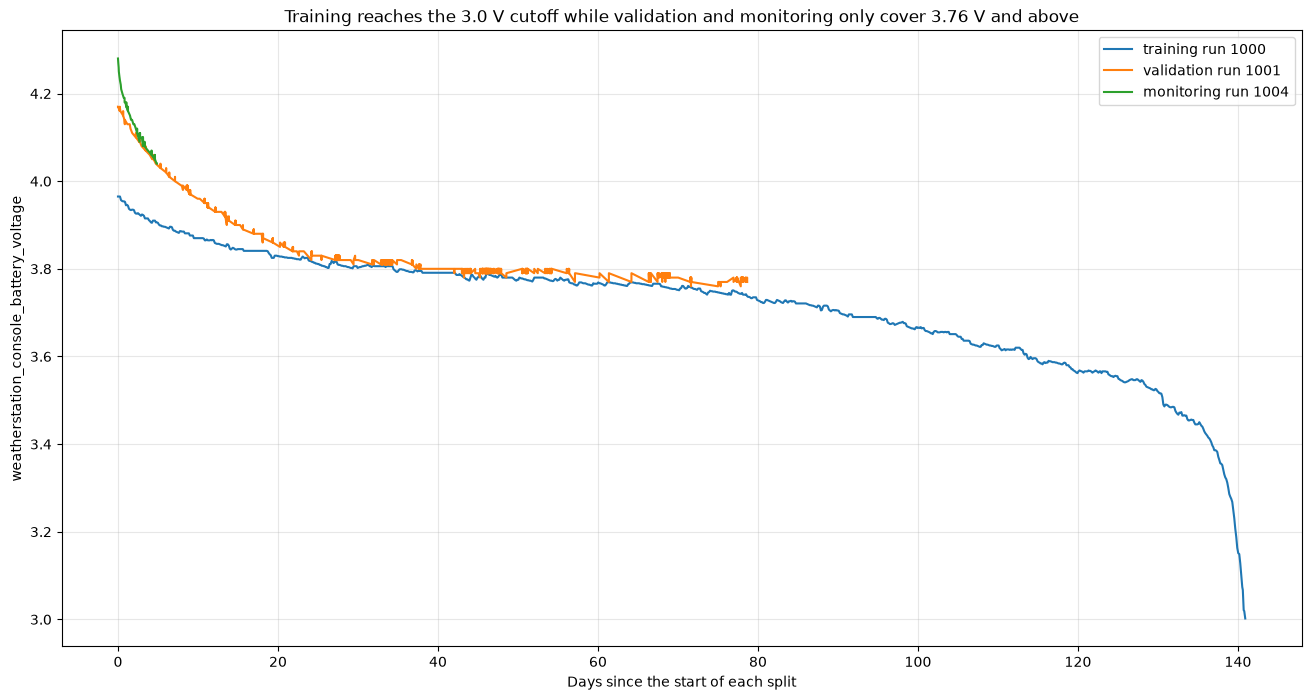

In [3]:
from mlmodels import prepare_plot, prepare_split

prepare_split(ws, training=ws.run(1000), validation=ws.run(1001), monitoring=ws.run(1004))
prepare_plot(ws, column=ws.inputs[0], align="start", title="Training reaches the 3.0 V cutoff while validation and monitoring only cover 3.76 V and above")

## Explore ([6.7.4](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#674-explore))

explore stateful exponential 1 h [state in helpers] rmse against deployed [4.34] bounce [0]
explore stateful exponential 1 h [state lost every 3 days] rmse against deployed [3.51] bounce [3]


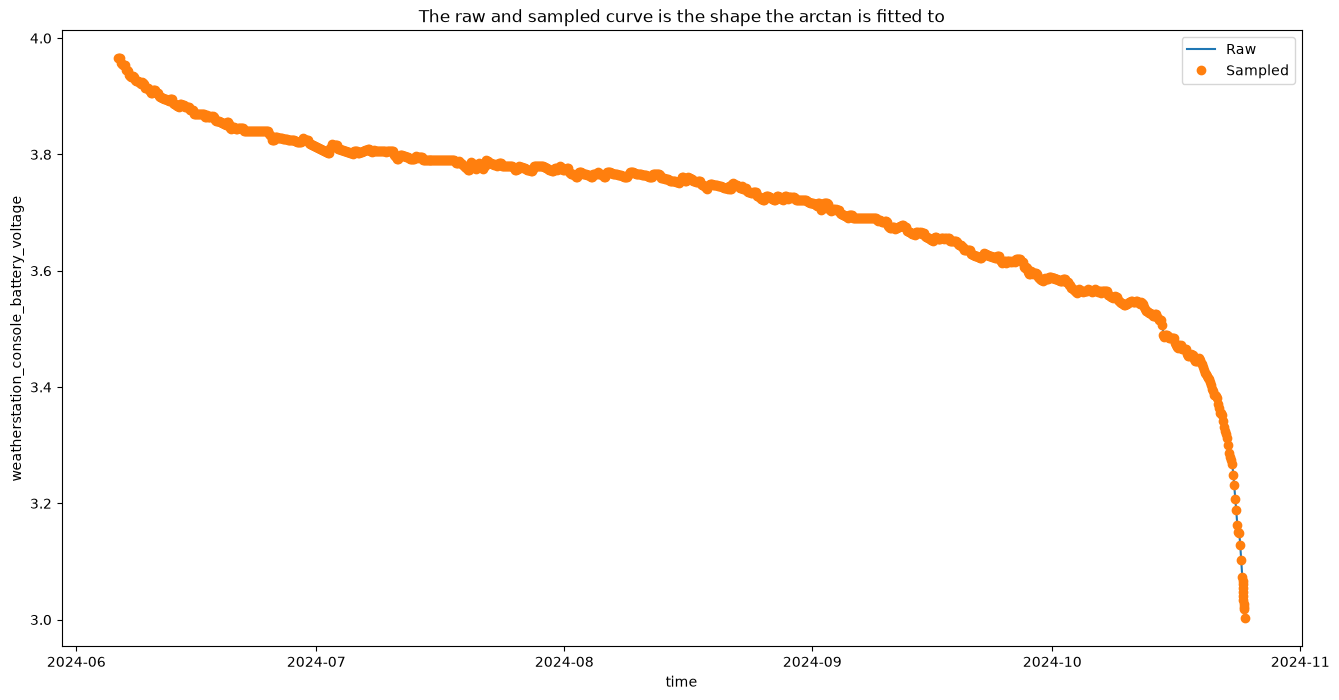

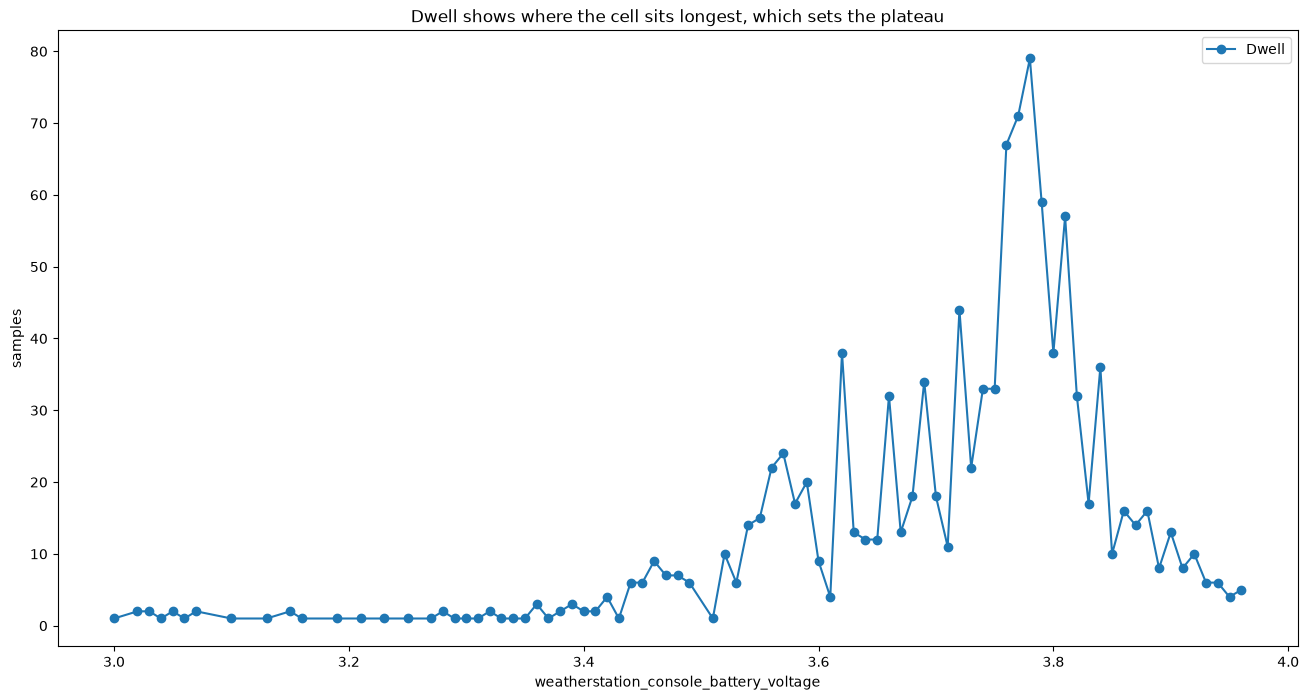

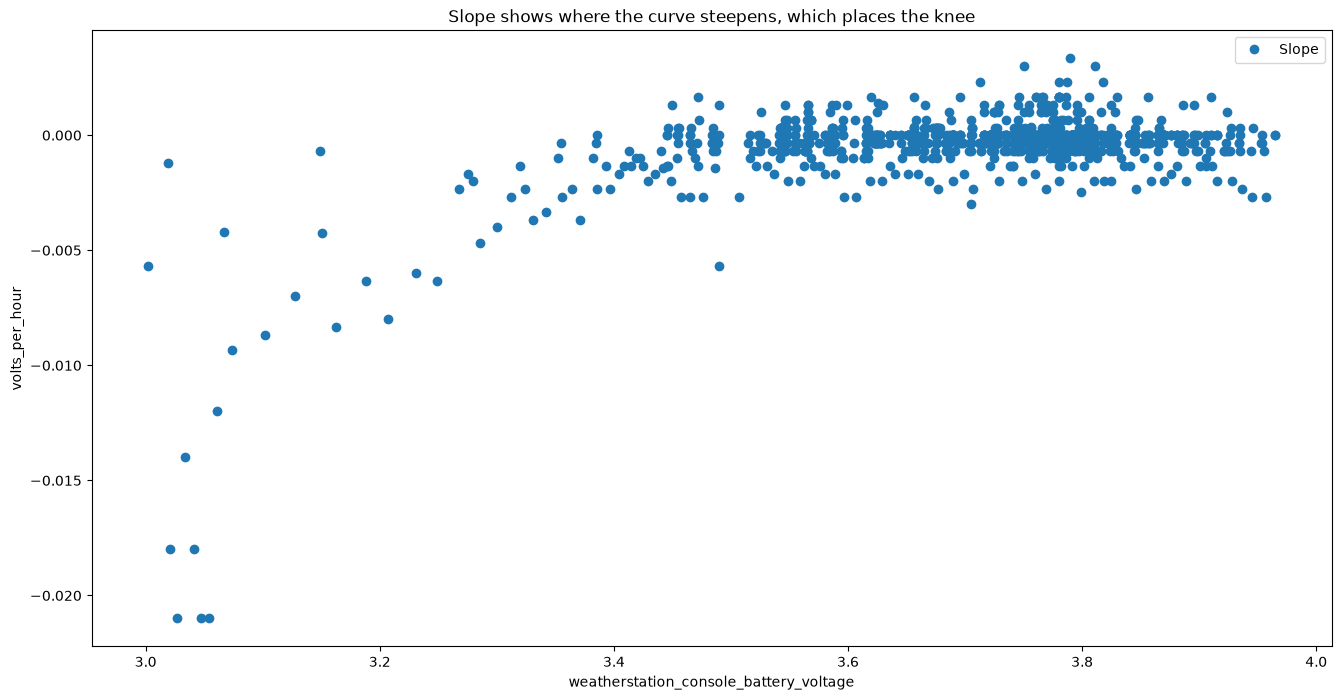

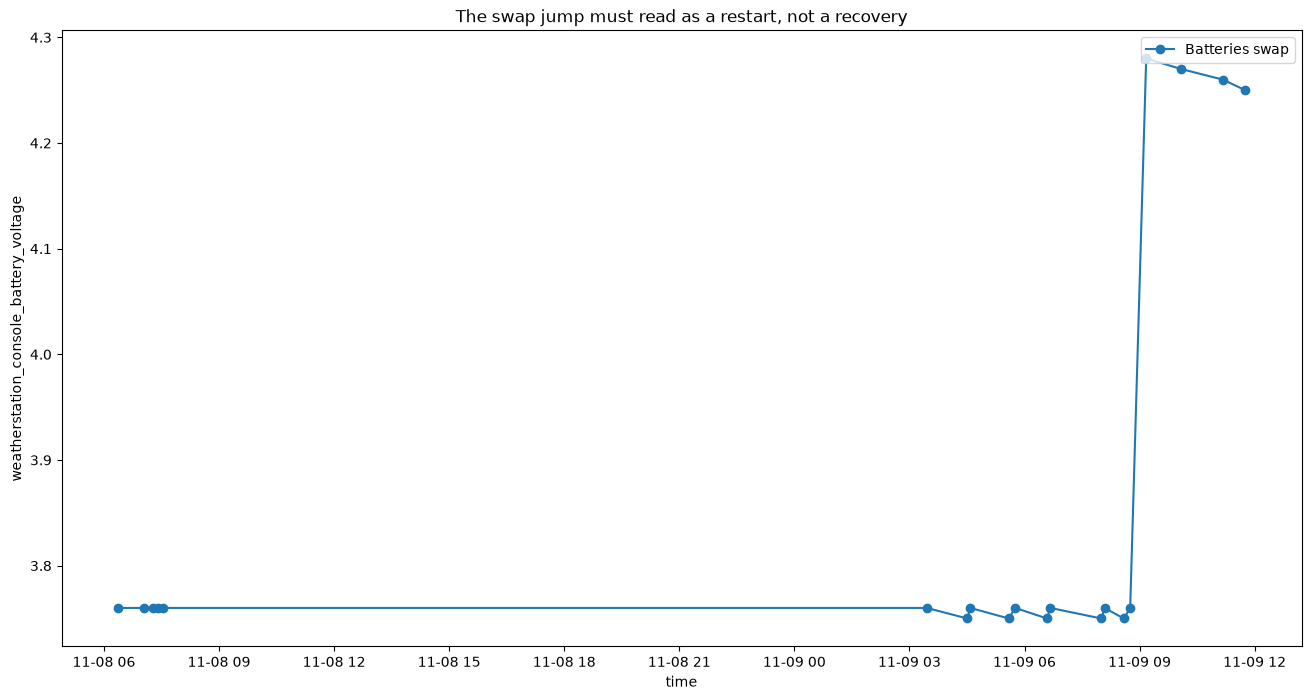

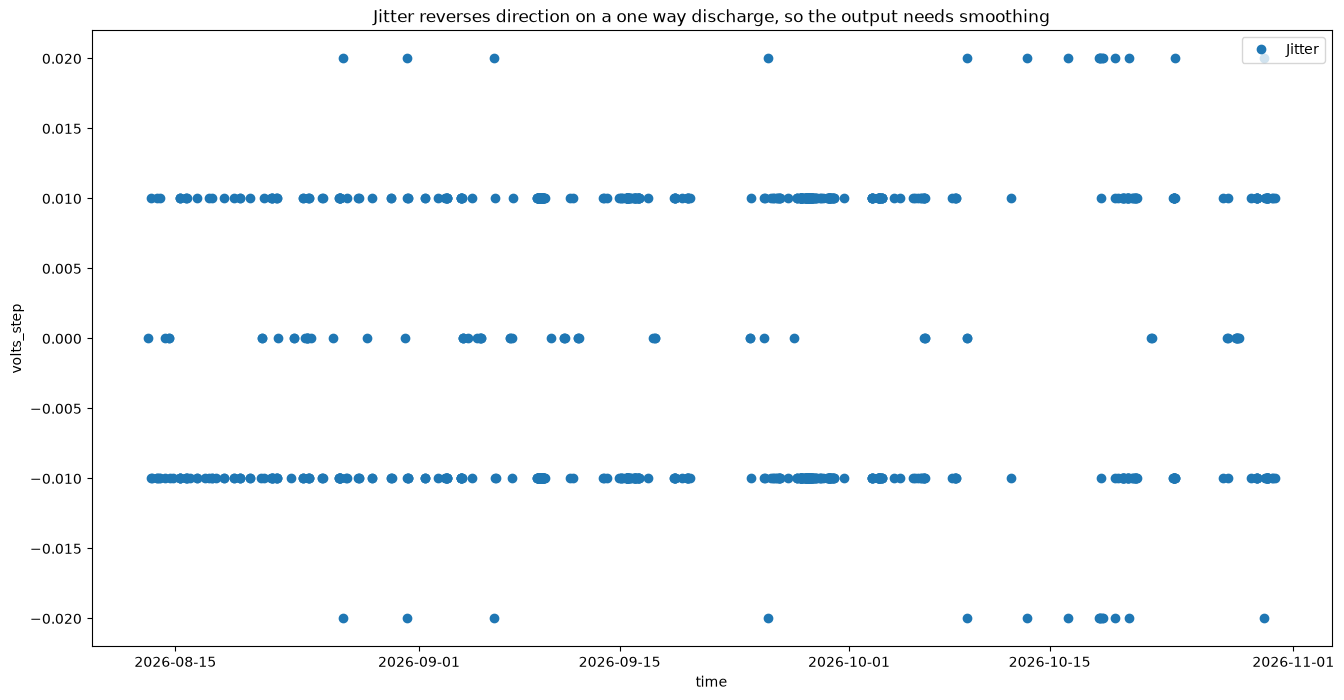

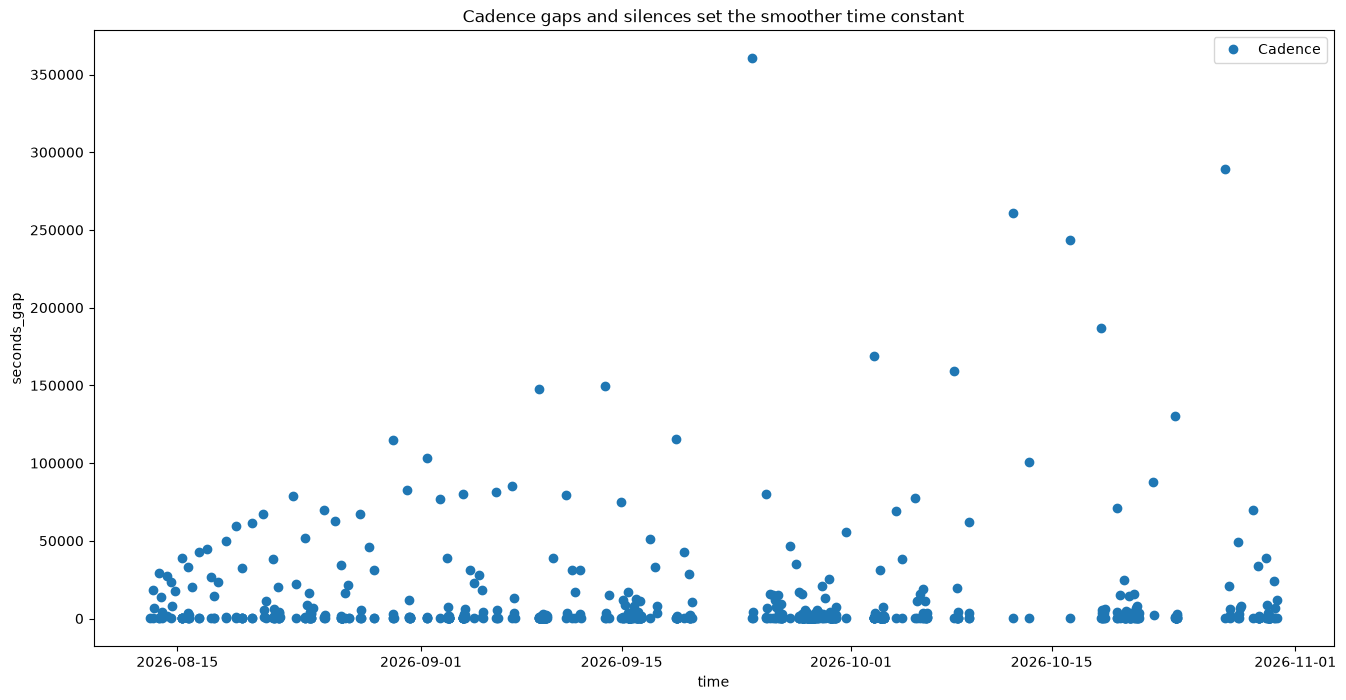

In [4]:
from math import atan, exp

import numpy as np
import polars as pl
from scipy.optimize import curve_fit

from mlmodels import explore_plot

explore_plot("Raw", ws.training, "time", ws.inputs[0], title="The raw and sampled curve is the shape the arctan is fitted to")
sampled_pl = ws.training.sort("time").group_by_dynamic("time", every="10m").agg(pl.col(ws.inputs[0]).min())
explore_plot("Sampled", sampled_pl, "time", ws.inputs[0], "o", overlay=True)

dwell_pl = ws.training.with_columns(pl.col(ws.inputs[0]).round(2)).group_by(ws.inputs[0]).agg(pl.len().alias("samples")).sort(ws.inputs[0])
explore_plot("Dwell", dwell_pl, ws.inputs[0], "samples", "o-", title="Dwell shows where the cell sits longest, which sets the plateau")

slope_pl = sampled_pl.with_columns((pl.col(ws.inputs[0]).diff() / (pl.col("time").diff().dt.total_seconds() / 3600)).alias("volts_per_hour")).drop_nulls()
explore_plot("Slope", slope_pl, ws.inputs[0], "volts_per_hour", "o", title="Slope shows where the curve steepens, which places the knee")

explore_plot("Batteries swap", ws.run(1003).frame, "time", ws.inputs[0], "o-", title="The swap jump must read as a restart, not a recovery")

measured_pl = ws.run(1001).frame
jitter_pl = measured_pl.with_columns(pl.col(ws.inputs[0]).diff().alias("volts_step")).drop_nulls("volts_step")
explore_plot("Jitter", jitter_pl, "time", "volts_step", "o", title="Jitter reverses direction on a one way discharge, so the output needs smoothing")

cadence_pl = measured_pl.with_columns(pl.col("time").diff().dt.total_seconds().alias("seconds_gap")).drop_nulls("seconds_gap")
explore_plot("Cadence", cadence_pl, "time", "seconds_gap", "o", title="Cadence gaps and silences set the smoother time constant")

capacity_pl = sampled_pl.drop("time").with_row_index("step").with_columns((100 - pl.col("step") / pl.col("step").max() * 100).alias("capacity"))
prototype_x = capacity_pl[ws.inputs[0]].to_numpy()
prototype_coefficients = curve_fit(
    lambda x, k, x0, y0: k * np.arctan(5.0 * (x - x0)) + y0, prototype_x, capacity_pl["capacity"].to_numpy(), p0=[30.0, 0.5 * (prototype_x.max() + prototype_x.min()), 50.0]
)[0]


def continuous_capacity(voltage):
    if voltage < prototype_x.min():
        return 0.0
    if voltage > prototype_x.max():
        return 100.0
    return min(max(prototype_coefficients[0] * atan(5.0 * (voltage - prototype_coefficients[1])) + prototype_coefficients[2], 0.0), 100.0)


def stateful_exponential(seconds, voltages, tau_seconds=3600, fall_margin=1.0, rise_margin=3.0, restart_seconds=None):
    outputs, smoothed, last, earlier, held = [], None, None, None, None
    next_restart = None if restart_seconds is None else seconds[0] + restart_seconds
    for second, voltage in zip(seconds, voltages, strict=True):
        if next_restart is not None and second >= next_restart:
            smoothed, held = None, None
            next_restart += restart_seconds
        previous, smoothed = smoothed, voltage
        if previous is not None and abs(voltage - previous) <= 0.05:
            smoothed = earlier + (previous - earlier) * exp(-(second - last) / tau_seconds)
        last, earlier = second, voltage
        capacity = continuous_capacity(smoothed)
        if held is None or capacity <= 0.0 or capacity >= 100.0 or capacity < held - fall_margin or capacity > held + 5 + rise_margin:
            held = float(int(capacity) // 5 * 5)
        outputs.append(held)
    return outputs


def reversals(values):
    moves = np.diff(values)
    moves = moves[moves != 0]
    return int((moves[1:] * moves[:-1] < 0).sum())


validation_seconds = ((ws.validation["time"] - ws.validation["time"].min()).dt.total_seconds()).to_list()
validation_volts = ws.validation[ws.inputs[0]].to_list()
deployed = ws.validation["template_weatherstation_console_battery_capacity_pct"].to_numpy()
for prototype, outputs in (
    ("state in helpers", stateful_exponential(validation_seconds, validation_volts)),
    ("state lost every 3 days", stateful_exponential(validation_seconds, validation_volts, restart_seconds=3 * 86400)),
):
    print(f"explore stateful exponential 1 h [{prototype}] rmse against deployed [{np.sqrt(np.mean((np.asarray(outputs) - deployed) ** 2)):.2f}] bounce [{reversals(np.asarray(outputs))}]")

## Train ([6.7.5](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#675-train))

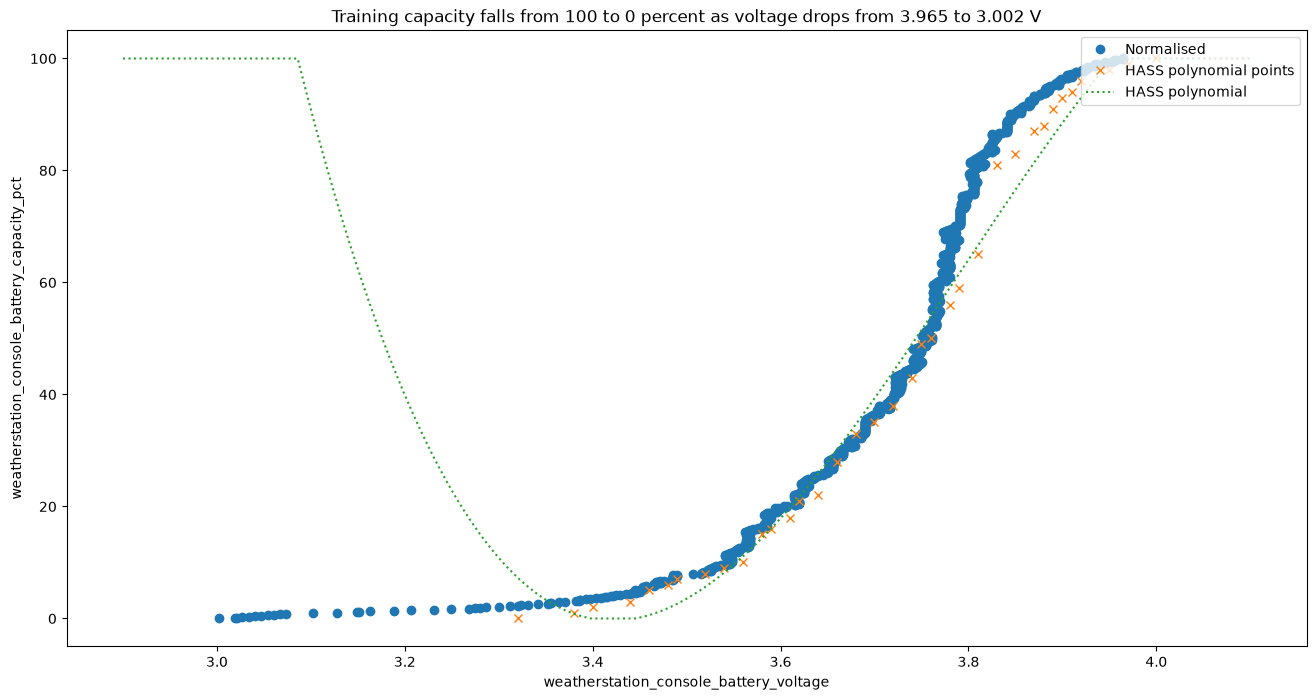

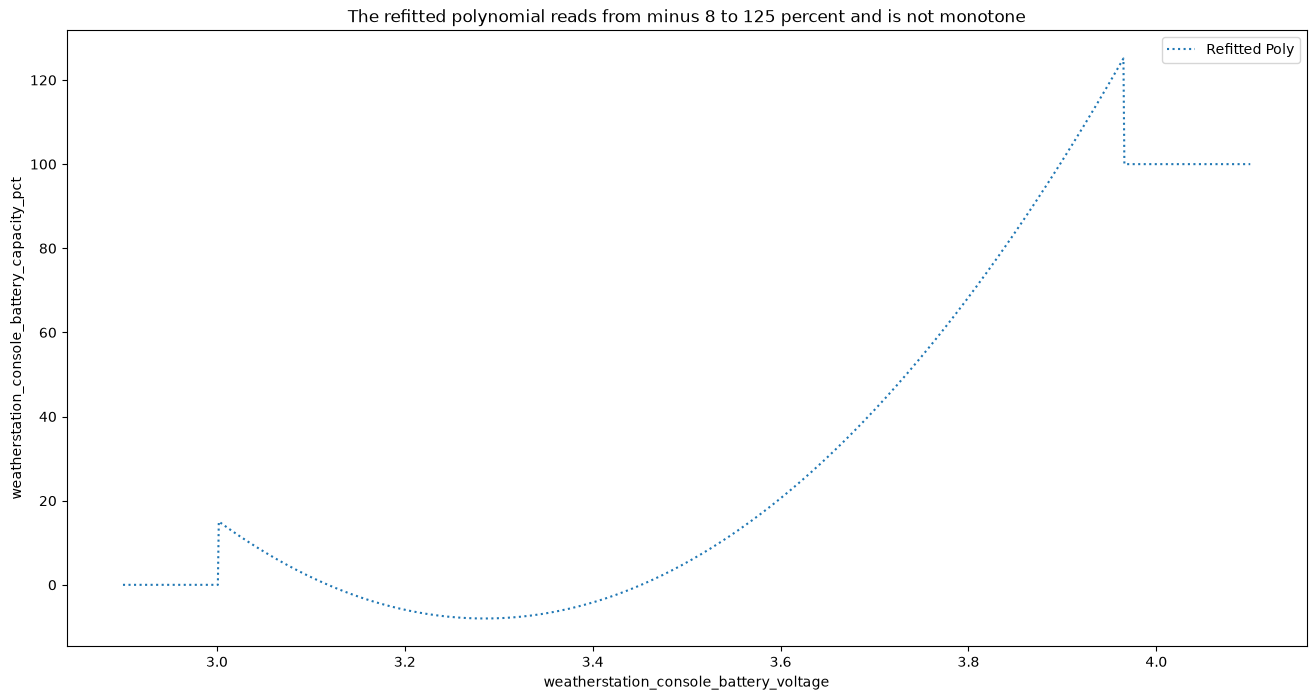

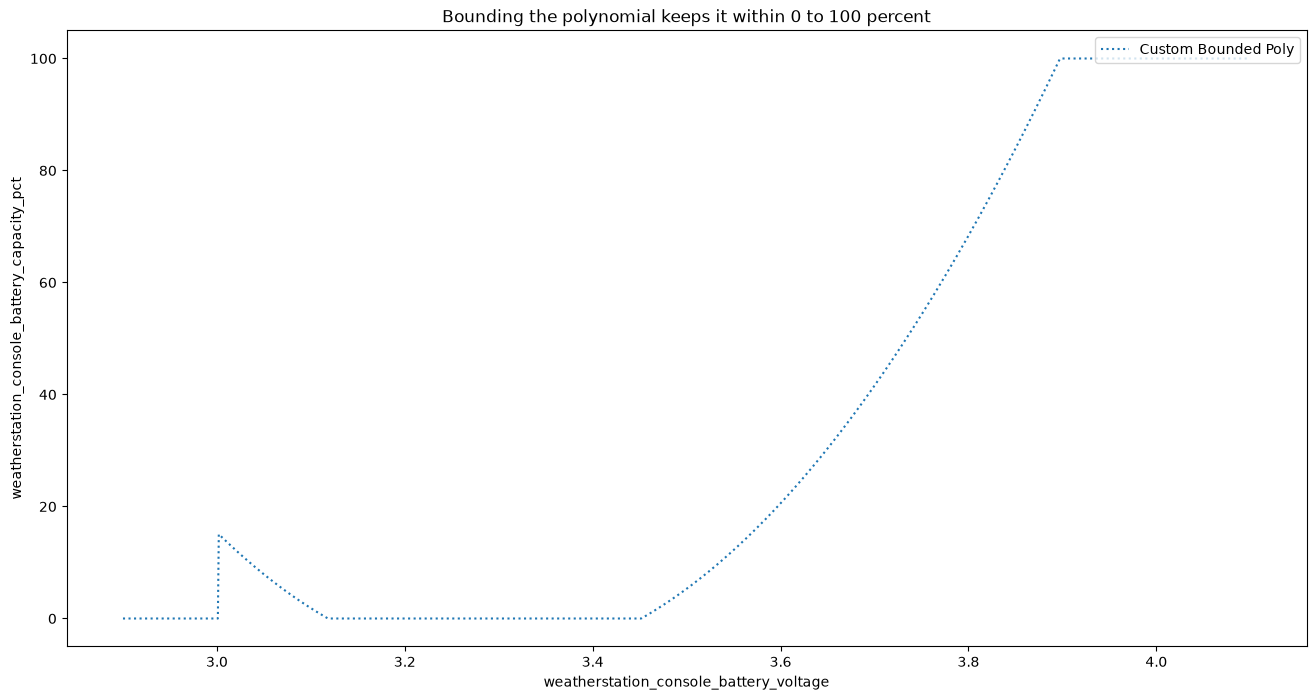

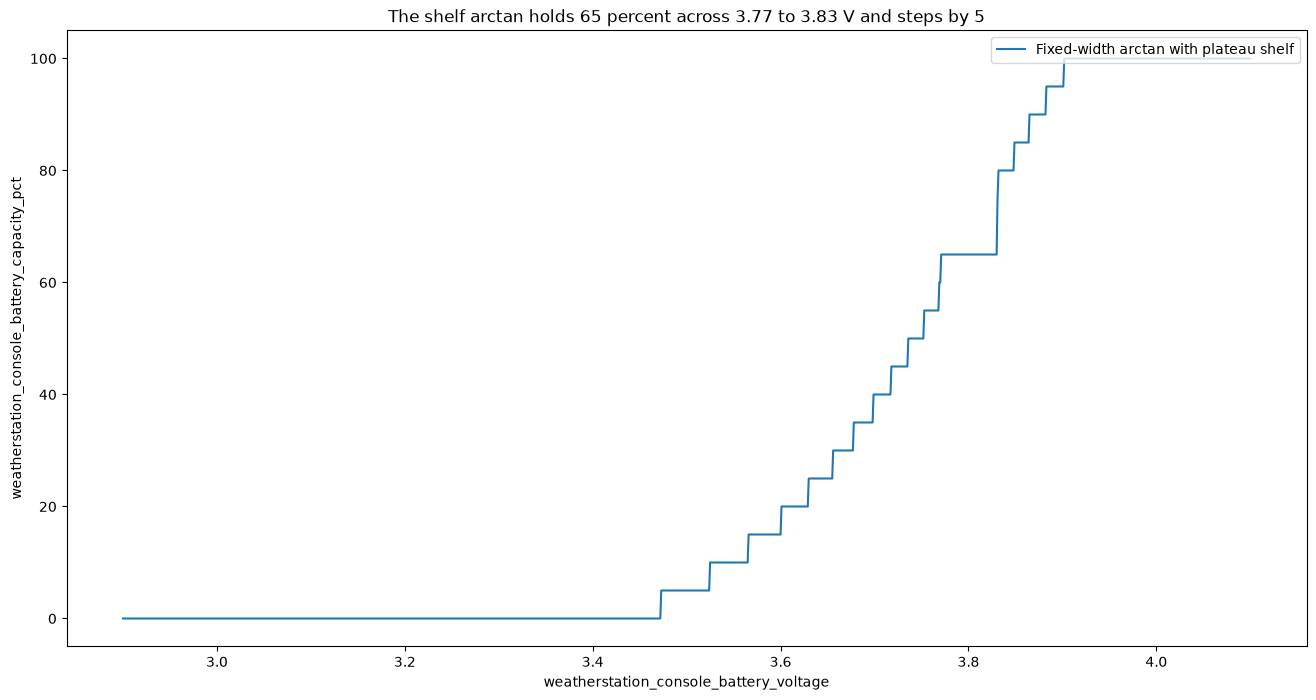

In [5]:
import numpy as np
import polars as pl
from scipy.optimize import curve_fit

from mlmodels import explore_plot

# The HASS polynomial points are lifted directly from the Home Assistant compensation curve and define the incumbent model.
hass_polynomial_points = np.array(
    [
        [4, 100],
        [3.97, 99],
        [3.95, 98],
        [3.92, 96],
        [3.91, 94],
        [3.9, 93],
        [3.89, 91],
        [3.88, 88],
        [3.87, 87],
        [3.85, 83],
        [3.83, 81],
        [3.81, 65],
        [3.79, 59],
        [3.78, 56],
        [3.76, 50],
        [3.75, 49],
        [3.74, 43],
        [3.72, 38],
        [3.7, 35],
        [3.68, 33],
        [3.66, 28],
        [3.64, 22],
        [3.62, 21],
        [3.61, 18],
        [3.59, 16],
        [3.58, 15],
        [3.56, 10],
        [3.54, 9],
        [3.52, 8],
        [3.49, 7],
        [3.48, 6],
        [3.46, 5],
        [3.44, 3],
        [3.4, 2],
        [3.38, 1],
        [3.32, 0],
    ]
)

sampled_pl = ws.training.sort("time").group_by_dynamic("time", every="10m").agg(pl.col(ws.inputs[0]).min())
data_normalised_pl = sampled_pl.drop("time").with_row_index(ws.outputs[0])
data_normalised_pl = data_normalised_pl.with_columns((100 - pl.col(ws.outputs[0]) / pl.max(ws.outputs[0]) * 100).alias(ws.outputs[0]))
y_min = 0.0
y_max = 100.0
y_data = data_normalised_pl.select(ws.outputs[0]).to_numpy().flatten()
x_min = data_normalised_pl.select(pl.min(ws.inputs[0])).item()
x_max = data_normalised_pl.select(pl.max(ws.inputs[0])).item()
x_data = data_normalised_pl.select(ws.inputs[0]).to_numpy().flatten()

poly_coefficients = np.polyfit(x_data, y_data, 2)
hass_coefficients = np.polyfit(hass_polynomial_points[:, 0], hass_polynomial_points[:, 1], 3)

ARCTAN_WIDTH = 5.0
arctan_coefficients = curve_fit(lambda x, k, x0, y0: k * np.arctan(ARCTAN_WIDTH * (x - x0)) + y0, x_data, y_data, p0=[30.0, 0.5 * (x_max + x_min), 0.5 * (y_max + y_min)])[0]
free_arctan_coefficients = curve_fit(lambda x, k, w, x0, y0: k * np.arctan(w * (x - x0)) + y0, x_data, y_data, p0=[1, 1, 0.5 * (x_max + x_min), 0.5 * (y_max + y_min)])[0]

# The shelf bounds are the 2026 plateau, set from validation because training holds no data on it.
shelf_low, shelf_high = 3.77, 3.83

ws.params = {
    "bounds": {"X_MIN": float(x_min), "X_MAX": float(x_max), "Y_MIN": y_min, "Y_MAX": y_max},
    "hass_poly": dict(zip(("HASS_A", "HASS_B", "HASS_C", "HASS_D"), map(float, hass_coefficients), strict=True)),
    "poly": dict(zip(("POLY_A", "POLY_B", "POLY_C"), map(float, poly_coefficients), strict=True)),
    "arctan": {**dict(zip(("K", "X0", "Y0"), map(float, arctan_coefficients), strict=True)), "W": ARCTAN_WIDTH},
    "free_arctan": dict(zip(("K", "W", "X0", "Y0"), map(float, free_arctan_coefficients), strict=True)),
    "shelf": {"SHELF_LOW": shelf_low, "SHELF_HIGH": shelf_high, "SHELF_CENTRE": 0.5 * (shelf_low + shelf_high)},
}

grid = np.linspace(2.9, 4.1, 1201)
poly_capacity = np.polyval(poly_coefficients, grid)
arctan_reading = np.where((grid >= shelf_low) & (grid <= shelf_high), ws.params["shelf"]["SHELF_CENTRE"], grid)
arctan_capacity = np.floor(np.clip(arctan_coefficients[0] * np.arctan(ARCTAN_WIDTH * (arctan_reading - arctan_coefficients[1])) + arctan_coefficients[2], y_min, y_max) / 5) * 5


def fitted_pl(capacity):
    return pl.DataFrame({ws.inputs[0]: grid, ws.outputs[0]: np.where(grid < x_min, y_min, np.where(grid > x_max, y_max, capacity))})


explore_plot("Normalised", data_normalised_pl, ws.inputs[0], ws.outputs[0], "o", title="Training capacity falls from 100 to 0 percent as voltage drops from 3.965 to 3.002 V")
explore_plot("HASS polynomial points", pl.DataFrame({ws.inputs[0]: hass_polynomial_points[:, 0], ws.outputs[0]: hass_polynomial_points[:, 1]}), ws.inputs[0], ws.outputs[0], "x", overlay=True)
explore_plot("HASS polynomial", pl.DataFrame({ws.inputs[0]: grid, ws.outputs[0]: np.clip(np.polyval(hass_coefficients, grid), y_min, y_max)}), ws.inputs[0], ws.outputs[0], ":", overlay=True)
explore_plot("Refitted Poly", fitted_pl(poly_capacity), ws.inputs[0], ws.outputs[0], ":", title="The refitted polynomial reads from minus 8 to 125 percent and is not monotone")
explore_plot("Custom Bounded Poly", fitted_pl(np.clip(poly_capacity, y_min, y_max)), ws.inputs[0], ws.outputs[0], ":", title="Bounding the polynomial keeps it within 0 to 100 percent")
explore_plot("Fixed-width arctan with plateau shelf", fitted_pl(arctan_capacity), ws.inputs[0], ws.outputs[0], "-", title="The shelf arctan holds 65 percent across 3.77 to 3.83 V and steps by 5")

## Define ([6.7.6](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#676-define))

In [6]:
from mlmodels import define_model

BOUNDS, HASS, POLY, ARCTAN, FREE_ARCTAN, SHELF = (ws.params[name] for name in ("bounds", "hass_poly", "poly", "arctan", "free_arctan", "shelf"))
X_MIN, X_MAX, Y_MIN, Y_MAX = BOUNDS["X_MIN"], BOUNDS["X_MAX"], BOUNDS["Y_MIN"], BOUNDS["Y_MAX"]
HASS_A, HASS_B, HASS_C, HASS_D = HASS["HASS_A"], HASS["HASS_B"], HASS["HASS_C"], HASS["HASS_D"]
POLY_A, POLY_B, POLY_C = POLY["POLY_A"], POLY["POLY_B"], POLY["POLY_C"]
Y_BOUNDS = {"Y_MIN": Y_MIN, "Y_MAX": Y_MAX}
K, X0, Y0, W = ARCTAN["K"], ARCTAN["X0"], ARCTAN["Y0"], ARCTAN["W"]
SHELF_LOW, SHELF_HIGH, SHELF_CENTRE = SHELF["SHELF_LOW"], SHELF["SHELF_HIGH"], SHELF["SHELF_CENTRE"]


def hass_poly(voltage, voltage_valid):
    if voltage_valid == 0:
        return Y_MIN, 0
    capacity = ((HASS_A * voltage + HASS_B) * voltage + HASS_C) * voltage + HASS_D
    return float(round(min(max(capacity, Y_MIN), Y_MAX))), 1


def refitted_poly(voltage, voltage_valid):
    if voltage_valid == 0:
        return Y_MIN, 0
    if voltage < X_MIN:
        return Y_MIN, 1
    if voltage > X_MAX:
        return Y_MAX, 1
    return (POLY_A * voltage + POLY_B) * voltage + POLY_C, 1


def bounded_poly(voltage, voltage_valid):
    if voltage_valid == 0:
        return Y_MIN, 0
    if voltage < X_MIN:
        return Y_MIN, 1
    if voltage > X_MAX:
        return Y_MAX, 1
    return min(max((POLY_A * voltage + POLY_B) * voltage + POLY_C, Y_MIN), Y_MAX), 1


def free_width_arctan(voltage, voltage_valid):
    from math import atan

    if voltage_valid == 0:
        return Y_MIN, 0
    if voltage < X_MIN:
        return Y_MIN, 1
    if voltage > X_MAX:
        return Y_MAX, 1
    capacity = K * atan(W * (voltage - X0)) + Y0
    if capacity < Y_MIN:
        return Y_MIN, 1
    if capacity > Y_MAX:
        return Y_MAX, 1
    return float(int(capacity) // 5 * 5), 1


def arctan(voltage, voltage_valid):
    from math import atan

    if voltage_valid == 0:
        return Y_MIN, 0
    if voltage < X_MIN:
        return Y_MIN, 1
    if voltage > X_MAX:
        return Y_MAX, 1
    capacity = K * atan(W * (voltage - X0)) + Y0
    if capacity < Y_MIN:
        return Y_MIN, 1
    if capacity > Y_MAX:
        return Y_MAX, 1
    return float(int(capacity) // 5 * 5), 1


def arctan_shelf(voltage, voltage_valid):
    from math import atan

    if voltage_valid == 0:
        return Y_MIN, 0
    if voltage < X_MIN:
        return Y_MIN, 1
    if voltage > X_MAX:
        return Y_MAX, 1
    reading = SHELF_CENTRE if SHELF_LOW <= voltage <= SHELF_HIGH else voltage
    capacity = K * atan(W * (reading - X0)) + Y0
    if capacity < Y_MIN:
        return Y_MIN, 1
    if capacity > Y_MAX:
        return Y_MAX, 1
    return float(int(capacity) // 5 * 5), 1


define_model(ws, model=1000, flavour="pyfunc", source=hass_poly, label="HASS polynomial", constants={**Y_BOUNDS, **HASS})
define_model(ws, model=1001, flavour="pyfunc", source=refitted_poly, label="Refitted polynomial", constants={**BOUNDS, **POLY})
define_model(ws, model=1002, flavour="pyfunc", source=bounded_poly, label="Bounded polynomial", constants={**BOUNDS, **POLY})
define_model(ws, model=1003, flavour="pyfunc", source=free_width_arctan, label="Free-width arctan, steps of 5", constants={**BOUNDS, **FREE_ARCTAN})
define_model(ws, model=1004, flavour="pyfunc", source=arctan, label="Fixed-width arctan, steps of 5", constants={**BOUNDS, **ARCTAN})
define_model(ws, model=1005, flavour="pyfunc", source=arctan_shelf, label="Fixed-width arctan with plateau shelf, steps of 5", constants={**BOUNDS, **ARCTAN, **SHELF})

Define model [1000] [HASS polynomial] as [pyfunc] with runs [1000]
Define model [1001] [Refitted polynomial] as [pyfunc] with runs [1000]
Define model [1002] [Bounded polynomial] as [pyfunc] with runs [1000]
Define model [1003] [Free-width arctan, steps of 5] as [pyfunc] with runs [1000]
Define model [1004] [Fixed-width arctan, steps of 5] as [pyfunc] with runs [1000]
Define model [1005] [Fixed-width arctan with plateau shelf, steps of 5] as [pyfunc] with runs [1000]


## Evaluate ([6.7.7](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#677-evaluate))

Evaluate model [1000] [HASS polynomial] on [validation] check [flagged] measured [0.0] limit [0] passed [True]
Evaluate model [1000] [HASS polynomial] on [validation] check [bounce] measured [652.0] limit [60] passed [False]
Evaluate model [1000] [HASS polynomial] on [validation] check [rmse_incumbent] measured [0.0] limit [5] passed [True]
Evaluate model [1000] [HASS polynomial] on [validation] check [linearity] measured [0.88] limit [0.9] passed [False]
Evaluate model [1000] [HASS polynomial] on [validation] check [rmse_deployed] measured [0.0] limit [0.5] passed [True]
Evaluate model [1001] [Refitted polynomial] on [validation] check [flagged] measured [0.0] limit [0] passed [True]
Evaluate model [1001] [Refitted polynomial] on [validation] check [bounce] measured [653.0] limit [60] passed [False]
Evaluate model [1001] [Refitted polynomial] on [validation] check [rmse_incumbent] measured [5.91] limit [5] passed [False]
Evaluate model [1001] [Refitted polynomial] on [validation] chec

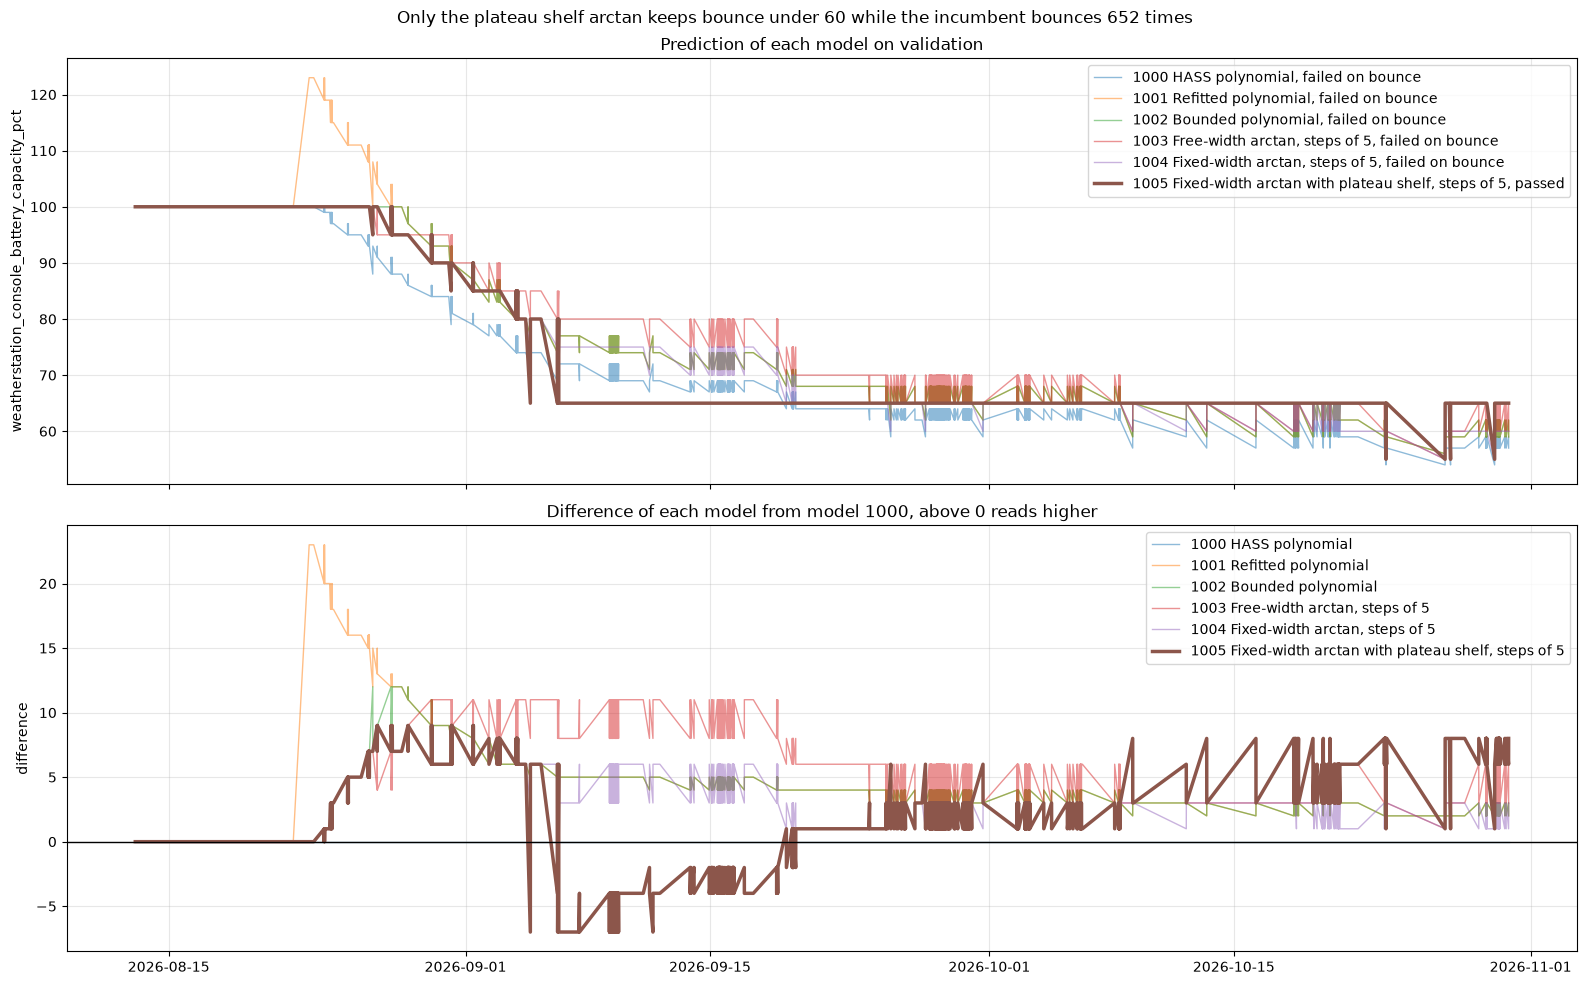

In [7]:
import numpy as np

from mlmodels import evaluate_gate, evaluate_metrics, evaluate_model, evaluate_models, evaluate_plot

DEPLOYED = "template_weatherstation_console_battery_capacity_pct"
INCUMBENT = 1000
BOUNCE_LIMIT = 60
PARITY_LIMIT = 0.5
AGREEMENT_LIMIT = 5
LINEARITY_LIMIT = 0.9


def bounces(values):
    moves = np.diff(values)
    moves = moves[moves != 0]
    return int((moves[1:] * moves[:-1] < 0).sum())


def acceptance_checks(model):
    output, flag = ws.outputs[0], ws.outputs[1]
    answer = evaluate_model(ws, model, "validation")
    predicted = answer[output]
    incumbent = evaluate_model(ws, INCUMBENT, "validation")[output]
    elapsed = (ws.validation["time"] - ws.validation["time"].min()).dt.total_seconds()
    linearity = evaluate_metrics(elapsed, predicted)["pearson_r"]
    checks = [
        {"split": "validation", "output": flag, "name": "flagged", "value": float((answer[flag] == 0).sum()), "limit": 0, "direction": "max"},
        {"split": "validation", "output": output, "name": "bounce", "value": float(bounces(predicted.to_numpy())), "limit": BOUNCE_LIMIT, "direction": "max"},
        {"split": "validation", "output": output, "name": "rmse_incumbent", "value": evaluate_metrics(incumbent, predicted)["rmse"], "limit": AGREEMENT_LIMIT, "direction": "max", "gate": False},
        {"split": "validation", "output": output, "name": "linearity", "value": None if linearity is None else -linearity, "limit": LINEARITY_LIMIT, "direction": "min", "gate": False},
    ]
    if model == INCUMBENT:
        checks.append(
            {"split": "validation", "output": output, "name": "rmse_deployed", "value": evaluate_metrics(ws.validation[DEPLOYED], predicted)["rmse"], "limit": PARITY_LIMIT, "direction": "max"}
        )
    return checks


for model in ws.models:
    evaluate_gate(ws, model, lambda model=model: acceptance_checks(model))
evaluate_models(ws)
evaluate_plot(ws, list(ws.models), "validation", reference=INCUMBENT, title="Only the plateau shelf arctan keeps bounce under 60 while the incumbent bounces 652 times")

## Package ([6.7.8](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#678-package))

In [8]:
import numpy as np

from mlmodels import package_model

x_min, x_max = ws.params["bounds"]["X_MIN"], ws.params["bounds"]["X_MAX"]
SHELF_LOW, SHELF_HIGH, SHELF_CENTRE = (ws.params["shelf"][name] for name in ("SHELF_LOW", "SHELF_HIGH", "SHELF_CENTRE"))

voltages = [round(v, 4) for v in [x_min - 0.1, x_min, *np.linspace(x_min, x_max, 40).tolist(), SHELF_LOW - 0.001, SHELF_LOW, SHELF_CENTRE, SHELF_HIGH, SHELF_HIGH + 0.001, x_max, x_max + 0.1]]
golden = {
    ws.inputs[0]: [*voltages, 0.0, 3.8, None, 3.8],
    ws.inputs[1]: [*[1] * len(voltages), 0, 0, 1, None],
    "expect": [*["ok"] * (len(voltages) + 2), "error", "ok"],
}
package_model(ws, 1005, golden, target={"kind": "served"})

Package model [1005] [Fixed-width arctan with plateau shelf, steps of 5] as [pyfunc] to target [served] with project [35cdf145cf06]
Package replayed [53] golden steps exactly through the shipped runtime


## Register ([6.7.9](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#679-register))

In [9]:
from mlmodels import register_model

register_model(ws, 1005)

Register model [1005] [Fixed-width arctan with plateau shelf, steps of 5] as version [1] with alias [preview]
Register model [1005] at [https://mlflow.proxy.janeandgraham.com/#/models/homeassistant_weatherstation_battery_1001/versions/1]
Register model [1005] release is set by hand after review
